# Figura 4: entropia e expoente de Lyapunov (identidade de Pesin)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SEU-USUARIO/pendulo-caotico/blob/main/04_entropia_e_pesin.ipynb)

Notebook de apoio ao artigo *Caracterização do caos no pêndulo forçado e amortecido: instabilidade, informação e geometria do espaço de fase*, **Seção IV, Figura 4**.

A produção de informação do pêndulo é medida por dois caminhos independentes, que depois são comparados.

1. **Caminho dinâmico.** O expoente de Lyapunov, obtido da dinâmica tangente, dá a entropia de Kolmogorov-Sinai pela identidade de Pesin, Eq. (7): $h_{\mathrm{KS}} = \sum_{\lambda_i>0}\lambda_i = \lambda_1 T_d$ por período do forçamento.
2. **Caminho observacional.** A *Sample Entropy* (SampEn) é calculada apenas da série estroboscópica $u_n = \theta(t_0 + nT_d)$, sem usar as equações de movimento. Para dimensão de imersão $m$ grande, ela aproxima a entropia de correlação $K_2$ de Grassberger e Procaccia, que satisfaz $K_2 \le h_{\mathrm{KS}}$.

O painel (a) compara os dois caminhos ao longo de $f \in [0{,}9;\ 1{,}5]$. O painel (b) examina o regime caótico $f = 1{,}2$ e mostra por que $K_2$ fica abaixo de $h_{\mathrm{KS}}$. No fim, o notebook verifica o horizonte de previsibilidade que $h_{\mathrm{KS}}$ impõe.

**Tempo de execução:** cerca de 1 minuto e meio. O custo vem da SampEn, que compara todos os pares de trechos da série (custo proporcional a $N^2$).

## Código

### 1. Bibliotecas e parâmetros

Mesmo sistema dos notebooks anteriores ($q$ = `beta` = 0,5; $\Omega = 2/3$), com 100 passos de RK4 por período.

In [1]:
# Dependências: numpy, matplotlib e numba.
# No Colab o Numba normalmente já vem instalado; se faltar, descomente a linha abaixo.
# !pip install numba

import math
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from numba import njit
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

beta  = 0.5                 # amortecimento q
Omega = 2/3                 # frequência do forçamento
T_D   = 2*math.pi/Omega     # período do forçamento
SPP   = 100                 # passos por período
DT    = T_D/SPP             # passo de integração

PUR, RED, ORA = '#6a3d9a', '#b2182b', '#d95f02'   # cores da figura

FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

### 2. Integrador: estado e vetor tangente

`deriv` devolve as derivadas do estado $(\theta, \omega)$, Eq. (3), e do vetor tangente $(a, b) = (\delta\theta, \delta\omega)$, Eq. (6). `rk4` dá um passo de Runge-Kutta de 4ª ordem nas quatro variáveis.

In [2]:
@njit
def deriv(tt, x, y, a, b, f):
    # estado (theta, omega) + vetor tangente (a, b)
    return (y,
            -beta*y - math.sin(x) + f*math.cos(Omega*tt),
            b,
            -math.cos(x)*a - beta*b)

@njit
def rk4(t, th, w, a, b, dt, f):
    x1, y1, a1, b1 = deriv(t, th, w, a, b, f)
    t2 = t + dt/2
    x2, y2, a2, b2 = deriv(t2, th + dt*x1/2, w + dt*y1/2, a + dt*a1/2, b + dt*b1/2, f)
    x3, y3, a3, b3 = deriv(t2, th + dt*x2/2, w + dt*y2/2, a + dt*a2/2, b + dt*b2/2, f)
    x4, y4, a4, b4 = deriv(t + dt, th + dt*x3, w + dt*y3, a + dt*a3, b + dt*b3, f)
    return (th + dt/6*(x1 + 2*x2 + 2*x3 + x4),
            w  + dt/6*(y1 + 2*y2 + 2*y3 + y4),
            a  + dt/6*(a1 + 2*a2 + 2*a3 + a4),
            b  + dt/6*(b1 + 2*b2 + 2*b3 + b4))

### 3. Uma trajetória: série $\theta_n$ e estiramento $\ell_n$

A função `run` faz três etapas.

1. **Transiente** de `n_trans` períodos, só com o estado.
2. **Alinhamento** de `align` períodos. O vetor tangente, iniciado em $(1, 0)$, gira até a direção de maior crescimento. Sem essa etapa, os primeiros valores de estiramento seriam enviesados pela direção inicial arbitrária.
3. **Registro** de `n_rec` períodos. Em cada um guarda $\theta_n$ reduzido a $(-\pi, \pi]$ e o estiramento

$$\ell_n = \ln\frac{\lVert\delta x_{n+1}\rVert}{\lVert\delta x_n\rVert},$$

renormalizando o vetor em seguida. A média de $\ell_n$ é $\lambda_1 T_d$, ou seja, $h_{\mathrm{KS}}$ em nats por período.

A função também devolve o estado final, usado como condição inicial do próximo $f$ na varredura.

In [3]:
@njit
def run(f, th, w, n_trans, n_rec, align=30):
    # transiente + registro: theta estroboscópico e estiramento l = ln|dx| por período
    t = 0.0

    # 1) transiente
    for n in range(n_trans):
        for _ in range(SPP):
            th, w, _, _ = rk4(t, th, w, 0.0, 0.0, DT, f)
            t += DT

    # 2) alinha o vetor tangente com a direção instável
    a, b = 1.0, 0.0
    for n in range(align):
        for _ in range(SPP):
            th, w, a, b = rk4(t, th, w, a, b, DT, f)
            t += DT
        r = math.hypot(a, b)
        a /= r
        b /= r

    # 3) registro
    TH = np.empty(n_rec)
    L = np.empty(n_rec)
    for n in range(n_rec):
        for _ in range(SPP):
            th, w, a, b = rk4(t, th, w, a, b, DT, f)
            t += DT
        r = math.hypot(a, b)
        L[n] = math.log(r)                           # estiramento no período
        a /= r
        b /= r
        TH[n] = math.atan2(math.sin(th), math.cos(th))   # theta em (-π, π]
    return TH, L, th, w

### 4. Sample Entropy, Eq. (8)

Formam-se vetores $\mathbf u_i^{(m)} = (u_i, \dots, u_{i+m-1})$ a partir da série. Conta-se $B$, o número de pares $(i, j)$ cuja distância de Chebyshev (a maior diferença componente a componente) é menor que $r$, e $A$, quantos desses pares continuam próximos quando se inclui a amostra seguinte, $u_{i+m}$ e $u_{j+m}$. Então

$$\mathrm{SampEn}(m, r, N) = -\ln\frac{A}{B},$$

em que $A/B$ é a probabilidade de que trechos semelhantes por $m$ períodos continuem semelhantes no período seguinte. Seguindo Richman e Moorman, pares de um trecho consigo mesmo não são contados, e $A$ e $B$ usam o mesmo conjunto de índices.

Como $\theta$ é um ângulo, a diferença entre duas amostras é medida no círculo: se $|u_i - u_j| > \pi$, usa-se $2\pi - |u_i - u_j|$. Sem isso, $\theta = \pi - \epsilon$ e $\theta = -\pi + \epsilon$, que são quase o mesmo ângulo, pareceriam distantes.

A função devolve `nan` se $B = 0$ (nenhum par semelhante) e `inf` se $A = 0$.

In [4]:
@njit
def sampen_circ(u, m, r):
    # SampEn (Richman-Moorman) com distância de Chebyshev circular (theta é ângulo)
    N = len(u)
    B = 0
    A = 0
    TWO = 2*math.pi
    for i in range(N - m):
        for j in range(i + 1, N - m):
            # distância entre os trechos de comprimento m
            d = 0.0
            for k in range(m):
                dk = abs(u[i + k] - u[j + k])
                if dk > math.pi:
                    dk = TWO - dk
                if dk > d:
                    d = dk
            if d < r:
                B += 1
                # o par continua próximo na amostra m+1?
                dm = abs(u[i + m] - u[j + m])
                if dm > math.pi:
                    dm = TWO - dm
                if dm < r:
                    A += 1
    if B == 0:
        return np.nan
    if A == 0:
        return np.inf
    return -math.log(A/B)

### 5. Horizonte de previsibilidade

Para testar a leitura de $h_{\mathrm{KS}}$ como taxa de perda de informação, `horizon` sorteia `n_ic` pontos do atrator. Em cada um cria uma segunda trajetória deslocada de $\delta$ em $\theta$ e conta quantos períodos se passam até a diferença angular ultrapassar `thresh` = 1 rad (limite de 200 períodos).

Se a separação cresce como $\delta\,e^{h_{\mathrm{KS}}n}$, o horizonte é $n \approx \ln(\mathrm{thresh}/\delta)/h_{\mathrm{KS}}$, e cada fator $10^3$ na precisão inicial acrescenta $\ln(10^3)/h_{\mathrm{KS}}$ períodos.

In [5]:
@njit
def horizon(f, n_ic, delta, thresh):
    # períodos até duas trajetórias (separadas por delta em theta) divergirem > thresh
    np.random.seed(1)
    th, w, t = 0.2, 0.0, 0.0
    for n in range(800):                       # transiente
        for _ in range(SPP):
            th, w, _, _ = rk4(t, th, w, 0.0, 0.0, DT, f)
            t += DT
    out = np.empty(n_ic)
    for k in range(n_ic):
        # avança de 1 a 20 períodos para sortear um novo ponto do atrator
        for n in range(1 + np.random.randint(0, 20)):
            for _ in range(SPP):
                th, w, _, _ = rk4(t, th, w, 0.0, 0.0, DT, f)
                t += DT
        t1 = t
        a1, b1 = th, w                         # trajetória de referência
        a2, b2 = th + delta, w                 # trajetória perturbada
        n = 0
        while n < 200:
            for _ in range(SPP):
                a1, b1, _, _ = rk4(t1, a1, b1, 0.0, 0.0, DT, f)
                a2, b2, _, _ = rk4(t1, a2, b2, 0.0, 0.0, DT, f)
                t1 += DT
            n += 1
            if abs(math.atan2(math.sin(a1 - a2), math.cos(a1 - a2))) > thresh:
                break
        out[k] = n
    return out

### 6. Painel (a): varredura em $f$

$f$ vai de 0,90 a 1,50 com passo 0,005 (121 valores). Como no Notebook 03, usa-se continuação: o estado final de um $f$ é a condição inicial do seguinte. Para cada $f$ há 400 períodos de transiente e 8 000 registrados.

- **Tolerância.** $r = 0{,}2\,\sigma_u$ é fixada uma vez, com o desvio-padrão $\sigma_u$ da série em $f = 1{,}2$, e usada para todos os $f$. Um valor absoluto único mantém a mesma resolução em todo o domínio.
- **Dimensão de imersão.** Usa-se $m = 8$. Com $m$ pequeno, órbitas de período longo podem dar SampEn positiva espúria, porque trechos de poucas amostras não distinguem fases diferentes da órbita.
- **Lado dinâmico.** $h_{\mathrm{KS}}$ é a parte positiva de $\langle\ell\rangle$, isto é, $h_{\mathrm{KS}} = \lambda_1^{+} T_d$.

In [6]:
f_arr = np.round(np.arange(0.90, 1.5001, 0.005), 4)
TH = np.empty((len(f_arr), 8000))
H = np.empty(len(f_arr))
th, w = 0.2, 0.0
for i, f in enumerate(f_arr):
    TH[i], L, th, w = run(f, th, w, 400, 8000)
    H[i] = L.mean()                                  # = lambda1*T_D (nats/período)

j12 = int(np.argmin(abs(f_arr - 1.2)))
r_abs = 0.2*TH[j12].std()                            # mesma tolerância para todo f
S8 = np.array([sampen_circ(TH[i], 8, r_abs) for i in range(len(f_arr))])
hP = np.maximum(H, 0.0)                              # h_KS = lambda1^+ * T_D

print(f"r = 0,2 sigma = {r_abs:.3f} rad | corr(SampEn, h_KS) = {np.corrcoef(S8, hP)[0, 1]:.3f}")
print(f"maior SampEn nas janelas periódicas (lambda1<0): {np.max(S8[H < 0]):.3f}")

r = 0,2 sigma = 0.306 rad | corr(SampEn, h_KS) = 0.971
maior SampEn nas janelas periódicas (lambda1<0): -0.000


### 7. Painel (b): convergência em $m$ e flutuações do estiramento

Em $f = 1{,}2$, uma série de 60 000 períodos é dividida em três trechos de 20 000. A SampEn é calculada para $m = 2, \dots, 8$ em cada trecho; as barras de erro são o desvio-padrão entre os trechos.

A diferença entre $K_2$ e $h_{\mathrm{KS}}$ vem da não uniformidade do estiramento. $h_{\mathrm{KS}}$ é a média de $\ell_n$, enquanto $K_2$ pesa mais os trechos de menor estiramento. Para flutuações aproximadamente gaussianas, Eq. (9):

$$K_2 \simeq \langle\ell\rangle - \frac{\sigma_\infty^2}{2}, \qquad \sigma_\infty^2 = \lim_{n\to\infty}\frac{1}{n}\,\mathrm{Var}\Big(\sum_{k=1}^{n}\ell_k\Big).$$

No código, $\sigma_\infty^2$ é estimada com somas de $n = 200$ valores consecutivos de $\ell$, em janelas deslizantes obtidas da soma acumulada `cs`, sobre 400 000 períodos. Usa-se a variância das somas, e não a de cada $\ell_n$, porque ela inclui as correlações entre períodos vizinhos. A incerteza de $K_2$ vem da dispersão entre 10 blocos.

Esse cálculo usa só a dinâmica tangente, não a série de $\theta$. É, portanto, uma previsão independente do valor para o qual a SampEn deve convergir.

In [7]:
# convergência em m (série de theta)
u, _, _, _ = run(1.2, 0.2, 0.0, 800, 60000, align=1)
sig = u.std()
ms = np.arange(2, 9)
nb = 3
bs = len(u)//nb
SE = np.array([[sampen_circ(u[k*bs:(k+1)*bs], m, 0.2*sig) for k in range(nb)] for m in ms])
mu, sd = SE.mean(1), SE.std(1)

# flutuações do estiramento por período (só dinâmica tangente, sem a série)
_, ell, _, _ = run(1.2, 0.2, 0.0, 800, 400000, align=50)
hKS = ell.mean()
n = 200
cs = np.concatenate([[0.0], np.cumsum(ell)])
S = cs[n:] - cs[:-n]                        # somas de n valores consecutivos
K2 = hKS - (S.var()/n)/2

Lb = len(S)//10
K2b = [hKS - (S[k*Lb:(k+1)*Lb].var()/n)/2 for k in range(10)]
K2e = np.std(K2b)/math.sqrt(10)

print(f"f=1.2: h_KS=<l>={hKS:.3f} nats/periodo ({hKS/math.log(2):.2f} bits) | "
      f"K2(flutuacoes)={K2:.2f}±{K2e:.2f} | SampEn(m=8)={mu[-1]:.2f}")

f=1.2: h_KS=<l>=1.236 nats/periodo (1.78 bits) | K2(flutuacoes)=0.58±0.02 | SampEn(m=8)=0.64


### 8. Horizonte de previsibilidade em $f = 1{,}2$

Para cada $\delta$, 400 pares de trajetórias. A última coluna é a previsão $\ln(1/\delta)/h_{\mathrm{KS}}$, que ignora o fator de ordem 1 do limiar e o tempo que a perturbação leva para se alinhar com a direção instável. Por isso o que se compara são os **incrementos** entre linhas, não os valores absolutos.

In [8]:
for d in [1e-3, 1e-6, 1e-9]:
    hz = horizon(1.2, 400, d, 1.0)
    print(f"  horizonte, delta={d:.0e}: {hz.mean():.1f}±{hz.std():.1f} periodos | "
          f"ln(1/delta)/h_KS = {math.log(1/d)/hKS:.1f}")

  horizonte, delta=1e-03: 7.1±3.1 periodos | ln(1/delta)/h_KS = 5.6
  horizonte, delta=1e-06: 12.7±3.6 periodos | ln(1/delta)/h_KS = 11.2


  horizonte, delta=1e-09: 18.5±4.3 periodos | ln(1/delta)/h_KS = 16.8


### 9. Figura

Em (a), as faixas cinzas marcam os valores de $f$ com $\lambda_1 \le 0$ (janelas periódicas). Em (b), o *inset* mostra o histograma do estiramento por período $\ell$, com a média $\langle\ell\rangle = h_{\mathrm{KS}}$ em roxo.

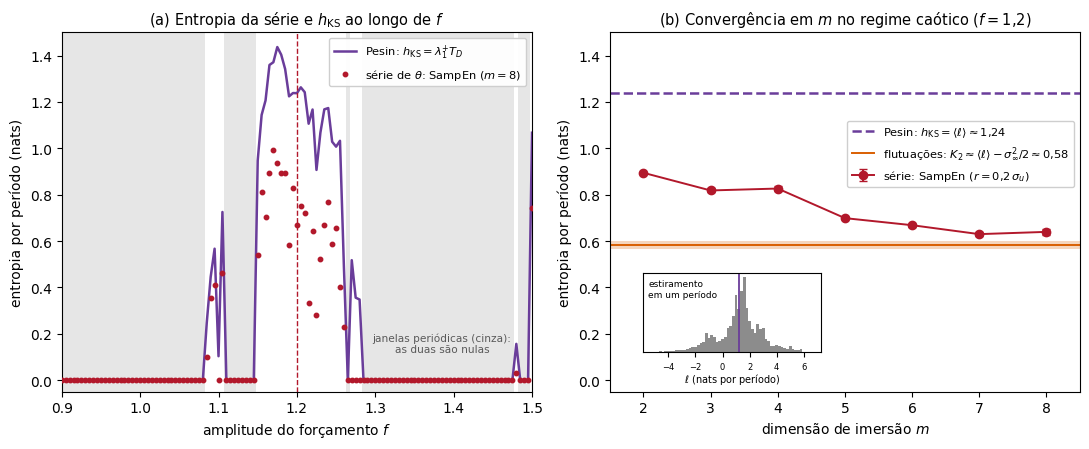

In [9]:
import warnings   # o inset não é compatível com tight_layout; o aviso é inofensivo
warnings.filterwarnings("ignore", message="This figure includes Axes that are not compatible")

c = lambda x: f"{x:.2f}".replace('.', '{,}')   # vírgula decimal nos rótulos

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6))

# ---- (a) varredura em f ----
for i in range(len(f_arr)):
    if H[i] <= 0:
        a1.axvspan(f_arr[i] - 0.0025, f_arr[i] + 0.0025, color='0.90', lw=0, zorder=0)
a1.plot(f_arr, hP, color=PUR, lw=1.8, label=r'Pesin: $h_{\mathrm{KS}}=\lambda_1^{+}T_D$', zorder=2)
a1.plot(f_arr, S8, 'o', color=RED, ms=3.2, label=r'série de $\theta$: SampEn ($m=8$)', zorder=3)
a1.axvline(1.2, color=RED, ls='--', lw=1)
a1.set_xlim(0.9, 1.5)
a1.set_ylim(-0.05, 1.5)
a1.set_xlabel(r'amplitude do forçamento $f$')
a1.set_ylabel('entropia por período (nats)')
a1.set_title(r'(a) Entropia da série e $h_{\mathrm{KS}}$ ao longo de $f$', fontsize=10.5)
a1.legend(loc='upper right', fontsize=8.2, framealpha=0.95)
a1.text(1.385, 0.12, 'janelas periódicas (cinza):\nas duas são nulas', fontsize=7.6, color='0.35', ha='center')

# ---- (b) convergência em m, f = 1,2 ----
a2.axhline(hKS, color=PUR, ls='--', lw=1.8, label=r'Pesin: $h_{\mathrm{KS}}=\langle\ell\rangle\approx' + c(hKS) + '$')
a2.axhspan(K2 - K2e, K2 + K2e, color=ORA, alpha=0.25, lw=0)
a2.axhline(K2, color=ORA, lw=1.4, label=r'flutuações: $K_2\approx\langle\ell\rangle-\sigma_\infty^2/2\approx' + c(K2) + '$')
a2.errorbar(ms, mu, yerr=sd, fmt='o-', color=RED, ms=6, lw=1.4, capsize=3, label=r'série: SampEn ($r=0{,}2\,\sigma_u$)')
a2.set_xlim(1.5, 8.5)
a2.set_ylim(-0.05, 1.5)
a2.set_xticks(ms)
a2.set_xlabel(r'dimensão de imersão $m$')
a2.set_ylabel('entropia por período (nats)')
a2.set_title(r'(b) Convergência em $m$ no regime caótico ($f=1{,}2$)', fontsize=10.5)
a2.legend(loc='upper right', bbox_to_anchor=(1.0, 0.77), fontsize=8.2, framealpha=0.95)

# inset: distribuição do estiramento por período
ax = inset_axes(a2, width='100%', height='100%', bbox_to_anchor=(0.07, 0.11, 0.38, 0.22),
                bbox_transform=a2.transAxes, loc='lower left', borderpad=0)
ax.hist(ell[:20000], bins=60, color='0.55', density=True)
ax.axvline(hKS, color=PUR, lw=1.3)
ax.set_xlabel(r'$\ell$ (nats por período)', fontsize=7, labelpad=0)
ax.tick_params(labelsize=6)
ax.set_yticks([])
ax.text(0.03, 0.92, 'estiramento\nem um período', transform=ax.transAxes, fontsize=6.5, va='top')

fig.tight_layout()
fig.savefig(FIG_DIR / 'figura4_entropia.png', dpi=170)
plt.show()

## Leitura dos resultados

Os números reproduzem os do artigo.

**Painel (a).** A SampEn, calculada só com a série de $\theta$, anula-se em todas as janelas periódicas e fica positiva nas bandas caóticas, acompanhando $h_{\mathrm{KS}}$ com correlação 0,971. (O valor impresso $-0{,}000$ nas janelas é o zero de ponto flutuante de $-\ln 1$.) O mapa de ordem e caos do Notebook 03 aparece sem o uso das equações de movimento. O caos fraco perto de $f \approx 1{,}10$ é detectado só em parte, porque fica confinado a bandas mais estreitas que a tolerância $r = 0{,}306$ rad.

**Painel (b).** Em $f = 1{,}2$, $h_{\mathrm{KS}} = \langle\ell\rangle = 1{,}236$ nats por período (1,78 bit). A SampEn decresce com $m$ e fica em torno de 0,64 para $m = 7$ e $8$, cerca de metade de $h_{\mathrm{KS}}$. A previsão das flutuações, obtida só com a dinâmica tangente, dá $K_2 \approx 0{,}58 \pm 0{,}02$, cerca de 10% abaixo do valor da série. O histograma do *inset* mostra a causa: $\ell$ varia de cerca de $-4$ a $+6$ nats em um único período, alternando contrações e expansões fortes. A diferença entre $K_2$ e $h_{\mathrm{KS}}$ mede essa não uniformidade, que o expoente médio sozinho não mostra.

**Horizonte.** Os horizontes médios são 7,1, 12,7 e 18,5 períodos para $\delta = 10^{-3}$, $10^{-6}$ e $10^{-9}$ rad. Os incrementos, 5,6 e 5,8 períodos, coincidem com a previsão $\ln(10^3)/h_{\mathrm{KS}} = 5{,}6$: cada ganho de mil vezes na precisão inicial acrescenta menos de seis períodos de previsão.

## Para explorar

- Troque a tolerância para `0.1*sig` ou `0.3*sig` no painel (b) e observe como a SampEn em $f = 1{,}2$ se desloca.
- Recalcule o painel (a) com $m = 2$ e procure valores positivos espúrios nas janelas periódicas.
- Adicione ruído à série (`u + 0.01*np.random.randn(len(u))`) e veja como a SampEn reage: é o que aconteceria com dados experimentais.